# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі в цьому ноутбуці запускаються **локально** через [Ollama](https://ollama.com), їх використання відбувається через HTTP-запити.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [ ]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [ ]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [ ]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.14


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [ ]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [ ]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [ ]:
QUESTION = "Яка столиця Франції?"

In [ ]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

### 1.3. Instruct: модель відповідає на питання

In [ ]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [ ]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 211 | генерація: 0.4 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакеті 4 яблука, тому 2 пакети — це **2 × 4 = 8 яблук**.
   - Тому після додавання:  
     $ 3 + 8 = 11 $ яблук у кошику.

3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:  
     $ 11 - 2 = 9 $ яблук у кошику.

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 647 | генерація: 1.2 с
--- міркування (1721 символів), початок:
Okay, let's see. So the problem is about Maria putting apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then Maria adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she adds in total. Each package is 4 apples, and there are 2 packages. So that's 4 times 2, which is 8. So adding 8 apples to the original 3, right?

Wait, let me check that again. Original apples: 3. T

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [ ]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 87 | генерація: 0.2 с
--- відповідь:
Слово **«трансформер»** має такі літери:

**т, р, а, н, с, т, о, м, и, р**

Підсумок:

- Літера **«р»** з'являється **2 рази**.

**Відповідь: 2 рази.**

=== think=True | токенів: 887 | генерація: 1.6 с
--- міркування (2485 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" (which is the Russian letter for "r") appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Wait, is that the correct spelling? Let me confirm. In Ukrainian, "transformation" is "трансформація", but the word given here is "трансформер". So, "transformation" in Ukrainian is "трансформація", but the user wrote "трансформер". Hmm, maybe it's a typo? Or maybe it's a different word. Let me check.

Wait, "трансформер" is the Ukrainian word for "tra …
--- відповідь:
Літера «р» трапляється **2 рази** в слові «трансформер». 

**Пояснення:**  

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [ ]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [ ]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [ ]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [ ]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [ ]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

fp16: готово


... (2 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [ ]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,8.04,8.64,14.67,2.67,2.40,56.71,23.93
int8,4.42,5.01,5.74,2.67,2.40,58.25,26.17
int4,2.73,3.32,2.86,2.81,2.76,55.90,29.79
int2,1.81,2.39,2.91,61102.12,33789316.00,0.24,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

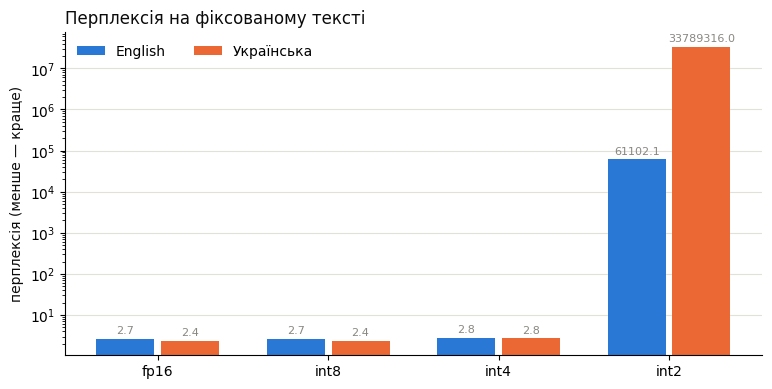

In [ ]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [ ]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",``thrown\nbetween 'ever'oft' \neverhosterone'...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}01\xb takent � taken...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0}'-'ever'ickets {'ever''}' \\'\...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.","}again \ %""樗\ %( firm \"" \ \'' betweenh '\ \..."
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...","fil��''}\n0. Heaven\n Fil'`0hber°,1 ,1a caught..."
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所etermineeverh \between betweenever婿 again \...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати лабораторну роботу до ...,"he economistwar"" be1.sever0 } again \ $} \}eve..."
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [ ]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з мінімальним використанням пам'яті. Це робиться для швидкого виконання моделей, особливо на пристроях з обмеженою відповідністю. Квантизація зменшує розмір ваг, змінюючи їх з плавних чисел (наприклад, 32-біт) до цілих або змінних (наприклад,

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [ ]:
VOTES = {1: "B", 2: "A", 3: "=", 4: "B", 5: "="}

In [ ]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

,запит,A,B,ваш вибір
0,Напиши короткий лист викладачеві з проханням п...,fp16,int4,int4
1,Поясни студентові першого курсу в 3–4 реченнях...,fp16,int4,fp16
2,Explain in three sentences why the sky is blue.,fp16,int4,однаково
3,Склади план підготовки до іспиту з програмуван...,int4,fp16,fp16
4,Write a Python function that checks whether a ...,int4,fp16,однаково


fp16 краща: 2, int4 краща: 1, однаково: 2


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [ ]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\\n again,  ten and whichotten in between win evidence tile between win had between between : : again again again again°\0 again which which had again between again again had again had had had had had had, which which again which9 which which in which   which in which in in in in which } in which Study which in which whichtbhousetbtbtbtbtbtbtbtb,househousehousehousehousehousehouse, in ...house doneettle,sdsdsdsd,uesdsdsd,sduesdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdificatesdsd: ...:’:ight ` which which “ which: which which which which which which which which which which which which which which which which which which which which which which which rest which which rest which resthouse :: which which again:sd: which

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\' \ \ \' 
 \ 0\' \ \'\'\'\'\'\'\'\'\'\' \ \ \ \ \ \ \ \ navigator \ \ 
 \ - DS  - - - - - - - - - - - - ~ ~ ~ taken  \ \ \ \ between \  hatchirst \ \\'\' \ - - - \INE \ \ -° - IN - between - found -国民  \ own%\ mark mark mark mark  mark mark mark             \ \          mark mark mark``h  \ mark mark mark mark mark  mark mark mark mark Mark Mark Mark Mark Mark attached  \ \  mark mark mark mark mark mark mark mark mark mark mark. mark mark mark, \ \ \ \ \n \   Paper mark, - \ mark\xb\xb \ \ - mark\n \ \ \ mark. \ Paper\n投 - \ \

## Відповіді на питання

1. ***У розділі 1.5 демо модель помиляється, рахуючи літеру «р» у слові «трансформер», — причому і без міркувань, і з ними. Поясніть, чому. Підтвердіть пояснення кодом.***\
Тому що моделі не читають текст по літерам, а сприймають його токенами, які потім перетворюються на абстрактні числові ID. Для моделі слово "трансформер" це просто набір декількох числових ID (наприклад [456, 8127, 331]) і вона не бачить ніяких літер у цих ID і намагається просто вгадати. Навіть з міркуваннями, коли модель намагається розбити слово на букви, вона намагається підібрати найімовірнішу відповідь і може помилитися, через малий розмір моделі.
2. ***Як у розділі 2.4 демо змінюються перплексія й метрики перекладу від fp16 до int2? Між якими варіантами стрибок найбільший?***\
По використанню ресурсів int8 зменшує споживання на 40%, int4 на 60% та int2 на 70% \
По швидкості генерації токенів int8 зменшує швидкість на 60%, а int4 та int2 на 80%.\
Перплексія. int8 повністю зберігла рівень перплексії, int4 зазнала невеликого її підвищення, а для int2 метрики зазнали великого стрибка і модель зламалась.\
Якість перекладу. Для int8 метрики перекладу трохи покращились, для int8 показник bleu покращився досить суттєво, але chrF трохи знизився, при int2 показники катастрофічно впали і модель втратила здатність перекладу.
3. ***Чи однаково зростає перплексія для англійської й української? Порівняйте з висновком зі слайду «Де просідає якість***\
Відповідно до презентації, якість для int8 залишилась майже незмінною. А для int4 та int2 перплексія зростає для української набагато швидше (int4: eng 2.67->2.81, ukr 2.4 -> 2.76, int2: eng: десятки тисяч, int4: десятки мільйонів). Це співпадає з висновком презентації.
4. ***Чи збігається ваш вибір у сліпому порівнянні (розділ 2.5 демо) з тим, що показали автоматичні метрики? Чи помітили ви різницю там, де метрики майже не змінилися, — або навпаки?*** \
Так, збігається. Метрики показали, що fp16 помірно краще за int4 для української мови та зовсім трохи краще для англійскої. Результати сліпого порівняння показали рівність результатів для англійскої мови та 2 голоса за fp16 проти 1 для int4 для україснької.
5. ***Знайдіть у таблиці перекладів (розділ 2.4 демо) правильний переклад, який відрізняється від еталона словами. Як на нього реагують BLEU і chrF?***\
Приклад: переклад речення "It is going to rain tomorrow, so take an umbrella." для fp16. BLEU реагує на це вкрай негативно, адже він спирається на точний збіг слів. chrF рахує ж не збіги слів, а послідовностей символів, тому реагує не так негативно, але також знижує оцінку.
6. ***У скільки разів зменшилася памʼять у таблиці розділу 2.4 демо і чому не рівно вдвічі, вчетверо й увосьмеро? Чи стала генерація швидшою?***\
Для int8 у 1.8 раза, для int4 у 2.9 раза та для int2 у 4.4 раза. Не рівно в 2,4,8 разів тому що квантизація не стискає всю модель цілком: KV-кеш, наприклад, не підлягає квантизації. Швидкість квантизації ж навпаки стає повільнішою, тому що під час генерації gpu повинно витрачати час та ресурси на деквантизацію.
7. ***Чому Base-модель у розділі 1.2 відповідає на питання новими питаннями? Сформулюйте промпт так, щоб Base-модель усе ж дала відповідь. Наведіть код і результат***\
Тому що модель навчана генерувати продовження тексту, а не відповіді, тому вона думає, що це питання належить до якоїсь вікторини чи тесту та продовжує генерувати питання. Промпт, щоб модель дала відповідь: "Місто, яке є столицею Франції, називається" (див. наступну клітинку)
8. ***Скільки токенів і часу забрали міркування в розділі 1.4 порівняно з відповіддю без міркувань? Чому модель міркує англійською, хоча питання українською?***\
Порівняно з відповіддю без міркувань кількість токенів і часу зросла втричі. Модель міркує англійською через те, що в навчальних даних переважна більшість текстів була на англійскькій мові, та тому що під час оцінки більшість інструкцій та винагород за правильну логіку даються англійською. Тому модель отримує запит українською, під час міркування перекладає його на англійській та міркує на ньому, а після отримання відповіді перекладає її на українську.
9. ***Знайдіть задачу, на якій режим міркування дає правильну відповідь, а без нього модель помиляється. Наведіть промпт і обидві відповіді***\
Задача про кулькі під склянками.\
Промпт: На столі стоять 3 склянки: Ліва, Середня і Права. Кулька лежить під Середньою склянкою. Я міняю місцями Ліву та Середню склянки. Потім міняю місцями Середню та Праву склянки. Потім міняю місцями Ліву та Праву склянки. Наостанок міняю місцями Ліву та Середню склянки. Де зараз кулька? Відповідай одним словом (Ліва / Середня / Права).\
Результат без міркування: Середня (неправильно)\
Результат з міркуванням: Права (правильно)
10. ***У функціях generate_raw і chat (розділ 1.1) стоять temperature: 0 і seed: 1. Навіщо?***\
Для детермінованості та відтворюваності результатів. temperature: 0 заставляє модель завжди обирати наступним найбільш ймовірний токен. seed: 1 задає конкретне початкове значення seed генератора псевдповипадкових чисел для запобігання будь-якої невизначеності.
11. ***Чому в секції 2 використовуємо fp16, а не bf16? Що показує torch.cuda.get_device_capability() на T4 і як це з цим повʼязано?***\
Тому що не всі GPU підтримують bf16. Функція get_device_capability() показує capability поточного пристрою та в нашому випадку вертає (7, 5), що відповідає версії 7.5, а підтримка типу bf16 з'явилась з версії 8.0.
12. ***Скільки параметрів у моделі з розділу 2.1 і скільки памʼяті має займати її fp16-версія за формулою з лекції? Порівняйте з «памʼяттю моделі» в таблиці розділу 2.4***\
У моделі 4 млрд. параметрів. За формулою з лекції вона повинна займати: 4 * 2 * 1.2(рахуємо overhead=20%) = 9.6GB. Пам'ять моделі в таблиці ж: 8.04GB
13. ***Що таке перплексія (розділ 2.2) і чому її не можна порівнювати між англійською й українською? Порахуйте перплексію fp16-моделі на випадковому наборі слів замість осмисленого тексту й поясніть результат***\
Перплексія це метрика якості квантизації, яка вимірює з якої кількості варіантів в середньому модель "вагалася" при обранні наступного токену. Чим ця метрика менша, тим "краще" модель знає мову. Її не можна порівнювати між англійською та українською мовами через різну структуру самих мов та оптимізації токенізаторів. Так, як перплексія розраховується на 1 токен, а більшість токенізаторів краще оптимізовано під англійську мову, то для токенізації слов для українською мови потрібно буде, в середньому, більше токенів. Внаслідов чого передбачити, наприклад, наступний токен-закінчення для українських слів буде простіше, ніж наступне нове слово в англійскій. Також на це впливає розподіл слів та ймовірностей для самої мови. Перплексія fp16-моделі на випадковому наборі слів (текст: Яблуко красивий дихає вовчок дідусь як Київ спати діапазон волохатий): 44.0 проти 2.4 на звичайному тексті. Якщо слова йдуть у випадковому порядку модель втрачає можливість коректно передбачувати наступний токен на основі минулого(окрім слів, які складаються з декількох токенів), тому ймовірність обрання токенів прямує до рівномірної.
14. ***Чому «пік VRAM» у таблиці розділу 2.4 більший за «памʼять моделі»? Що ще, крім ваг, займає памʼять під час генерації?***\
Тому що колонка "пам'ять моделі" відображає лише статичний розмір самих ваг моделі, тоді як "пік VRAM" - максимальний загальний обсяг відеопам'яті, задіяний GPU під час виконання обчислень та генерації тексту. Окрім ваг у ній зберігаються: KV-кеш, активації, буфер рантайму, буфери деквантизації
15. ***Скільки разів у сліпому порівнянні (розділ 2.5) ви обрали fp16, int4 чи «однаково»? Наскільки впевнено можна робити висновки з 5 порівнянь і скільки їх знадобилося б для надійного висновку?***/
2 рази було обрано fp16, 1 раз int4 та 2 рази "однаково". Не можна робити впевнених висновків з 5 порівнянь, це замало. Мінімальна кількість порівнянь для більш впевнених висновків - 25-30.
16. ***Як саме «ламається» модель у int2 (розділ 2.6)? Опишіть типові помилки у відповідях. Чи помітні їхні ознаки вже в int4?***\
Модель у int2 повністю руйнується та втрачає усі мовні здібності. Вона починає нескінчено повторювати одні й ті самі токени або короткі фрази, ігнорує мову запиту та суть інструкції, виводити спецсимволи. Ці ознаки вже помітні у int4, але вони ще не призводять до повної деградації тексту. Наприклад, при перекладі "The library is closed on Sundays and public holidays." модель виводить рядок "Бібліотека відкрита тільки з 1 по 7.", тобто рядок з ще коректних слів, але вже з частково втраченим сенсом.
17. ***Повторіть секцію 2 з меншою моделлю (наприклад, Qwen/Qwen3-1.7B). Чи сильніше квантизація бʼє по меншій моделі? Порівняйте перплексію й chrF з результатами для 4B***\
Повторення див. у клітинках нижче. Так, квантизація б'є сильніше по меншим моделям, через те, що у великих моделей є багато надлишкових параметрів, які компенсують похибку сусідніх нейронів при квантизації. Перплескія у меншої моделі в середньому в 2-3 рази вища, за 4B модель. chrF в 5-10 разів менший.
18. ***Поясніть принцип параметру OLLAMA_NUM_PARALLEL в ollama з демо?***\
Це параметр, який визначає скількі запитів одна й та сама модель може обробляти одночасно.
19. ***Чому майже всі сучасні моделі зберігаються в bf16?***\
Через його великий діапазон значень, який запобігає числовим переповненням та появи NaN під час навчання та роботи, що суттєво збільшує стабільність та якість моделі. А менша точність чисел bf16 навпроти майже не впливає на цю якість.
20. ***Для чого всі рантайми моделей слідують протоколу OpenAI? Як це повʼязано з ChatGPT?***\
Щоб забезпечити безшовну заміну рантайму або моделі. Прямогу зв'язку з ChatGPT немає, але є історичний зв'язок, бо коли ChatGPT спричинв бум на ринку, компанія OpenAI випустила публічний API для інтеграції їхньої нейромережі в продукти. Оскільки вони були першою великою компанією у цьому руслі усі нові продукти та інтерфейси створювались під їх протокол і наразі він став стандартом на ринку.

In [ ]:
print(generate_raw(BASE_MODEL, "Місто, яке є столицею Франції, називається"))

 Париж. Париж є одним з найбільших міст у світі і має величезну культурну, економічну та культурну значущість. Він є центром французької культури, мистецтва, економіки та туризму. Париж має величезну кількість музей, театрів, міських магазині


In [ ]:
compare_thinking(
    "На столі стоять 3 склянки: Ліва, Середня і Права. Кулька лежить під Середньою склянкою. Я міняю місцями Ліву та Середню склянки. Потім міняю місцями Середню та Праву склянки. Потім міняю місцями Ліву та Праву склянки. Наостанок міняю місцями Ліву та Середню склянки. Де зараз кулька? Відповідай одним словом (Ліва / Середня / Права)."
)

=== think=False | токенів: 54 | генерація: 0.6 с
--- відповідь:
**Середня**

Пояснення:  
Після трьох перестановок кулька відповідає положенню **Середньої** склянки.

=== think=True | токенів: 998 | генерація: 9.0 с
--- міркування (3514 символів), початок:
Okay, let's try to figure out where the ball is after all those swaps. So, there are three glass bottles: Left, Middle, and Right. The ball is initially under the Middle bottle. Then, the user swaps Left and Middle, then Middle and Right, then Left and Right again, and finally swaps Left and Middle again. I need to track the ball's position through each step.

First, let's note the initial positions. The ball is in the Middle bottle. Let's label them as positions 1 (Left), 2 (Middle), 3 (Right) for simplicity. Initially, position 2 has the ball.

First swap: Swap Left (1) and Middle (2). After …
--- відповідь:
Права



In [ ]:
import torch
torch.cuda.get_device_capability()

(7, 5)

In [ ]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))

model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=None)
print("Перплексія: ", perplexity(model, "Яблуко красивий дихає вовчок дідусь як Київ спати діапазон волохатий"))

del model
gc.collect()

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

Перплексія:  44.00438690185547


3831

In [ ]:
MODEL_ID = "Qwen/Qwen3-1.7B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

In [ ]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

fp16: готово


... (2 outputs left out)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int2: готово


In [ ]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,3.45,4.38,16.42,4.35,3.09,8.61,0.25
int8,2.04,2.98,11.47,4.46,3.11,9.13,0.25
int4,1.38,2.31,6.78,7.51,5.61,10.10,0.58
int2,1.03,1.96,6.67,441276.94,5894554.50,0.16,0.13


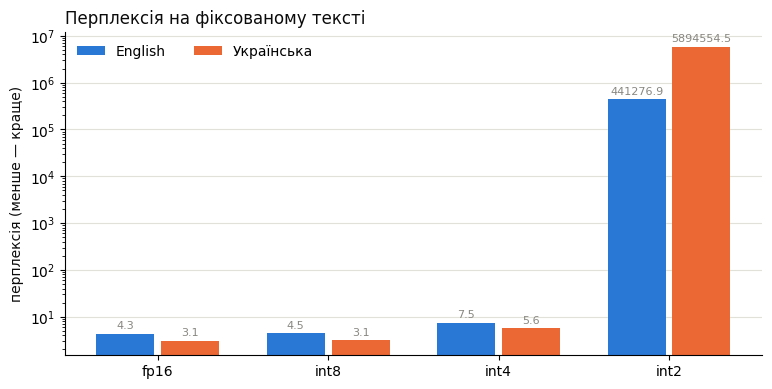

In [ ]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

In [ ]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...",<think>\n</think>\n\nВідмітка була змінена на ...,Kö良ça良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, let's tackle this translation. ...",çaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaça...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,"<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, so the user wants me to transla...",çaçaçaça Nelçaçaçaçaçaçaçaçaçaçaça_cc_lpancias...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...",<think>\n</think>\n\nВсього наша команда відре...,çaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaça/d...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, let's tackle this translation. ...",çaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaça...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, let's tackle this translation. ...",çaçaçaçaçaçaçaça良ça良ça良ça良良良良良良良良良良良良良良良良良良良良良...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,"<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...",<think>\n</think>\n\nЯ бажаю забічь таблі для ...,田田 rz rz rz rz rz л л rz_lp_lp_lp л rz_lp_lp_l...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,"<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, let's tackle this translation. ...",çaçaanelaanela.pg.pg.pg.pg.pg.pg.pgça.pgçaanel...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,"<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, let's tackle this translation. ...",çaçaçaçaçaçaçaçaçaçaça磊磊_cnçaça磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","<think>\nOkay, the user wants me to translate ...","<think>\nOkay, the user wants me to translate ...",<think>\n</think>\n\nЯкби сервер не відповідал...,ść pró良良良良良良良良良良良良良良良良良良良良良良天上良ancias良天上天上天上ic...


In [ ]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

<think>
Okay, the user wants a short letter to a professor asking to move the lab report submission to a week later due to illness. Let me start by understanding the key elements here.

First, the letter needs to be concise. It should include the student's name, the professor's name, the course, the original submission date, and the new date. The main request is to move the deadline to a week later because of illness. 

I should make sure to express the request politely and clearly. Maybe start with a greeting, state the purpose, mention the reason, and offer to provide any necessary documentation. Also, it's important to mention that the student is available to discuss the situation if needed.

I need to check for any specific formatting requirements, like the date, subject line, and closing. The tone should be respectful and professional. Avoid any technical jargon, keep it simple. Let me structure it step by step: subject line, greeting, body paragraphs with the request and

**int8:**

<think>
Okay, the user wants a short letter to a professor asking to move the lab report submission to a week later due to illness. Let me start by understanding the key elements here.

First, the letter needs to be concise. It should include the student's name, the professor's name, the course, the original submission date, and the new date. The main request is to move the deadline to a week later. The student should explain the reason, which is illness, and express gratitude.

I need to make sure the tone is polite and respectful. The student should mention the illness, perhaps specify the date, and ask for the flexibility. Also, include a thank you for the understanding. Let me check if there are any specific details the user might have missed. Since they didn't mention any, I'll keep it general.

Avoid any markdown, just plain text. Use formal language but keep it friendly. Maybe start with "Уважаючий [Препод

**int4:**

<think>
Okay, so I need to write a short list to a lecturer asking to transfer a lab assignment to a week through disease. Let me think about how to approach this.

First, the user wants a concise list. They might need to explain why the assignment was not done properly. Maybe the assignment was done on a week through disease, but now it's not. So, the request is to transfer the assignment to a week through disease.

Wait, maybe the original assignment was done on a week through disease, but now it's not. So, the user wants to transfer the assignment to a week through disease. But that's a bit confusing. Maybe the assignment was done on a week through disease, but now it's not, so they want to transfer it again?

Alternatively, maybe the user is asking to transfer the assignment to a week through disease, but the assignment was done on a week through disease. So, the request is to transfer the assignment to a week through disease again

**int2:**

hel helłow heliczłow hel hel钟 hel hel钟łow helłowłowłow钟钟łow钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟ça钟ça钟ça钟钟钟钟钟çaçaça钟钟钟ça钟钟钟钟çaçaça钟钟钟钟钟钟钟ça钟çaçaçaçaçaçaçaça钟钟钟ça钟钟钟钟钟ça钟钟钟 :

 :

钟_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc钟钟çaçaçaçaçaçaça_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_ccçaçaçaçaçaçaçaçaçaçaçaçaça_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc_cc

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

<think>
Okay, I need to write a Python function that checks if a string is a palindrome. Hmm, a palindrome is a string that reads the same forwards and backwards. So, like "madam" or "racecar". 

First, I should think about how to compare the string with its reverse. Oh right, one way is to reverse the string and check if it's equal to the original. But wait, what about case sensitivity? Like, if the input is "Racecar", it's not a palindrome because of the uppercase and lowercase letters. So maybe the function should ignore case and punctuation? Or maybe the problem assumes that the input is a simple string without special characters? The question doesn't specify, so maybe I should handle case insensitivity.

Wait, the problem says "a string", so maybe the function should check if the string is a palindrome, considering case. But sometimes people want to ignore case. Let me think. The user didn't specify, but maybe

**int8:**

<think>
Okay, I need to write a Python function that checks if a string is a palindrome. Hmm, a palindrome is a string that reads the same forwards and backwards. So, like "madam" or "racecar". 

First, I should think about how to compare the string with its reverse. Oh right, one way is to reverse the string and check if it's equal to the original. But wait, what about case sensitivity? Like, if the input is "Racecar", it's not a palindrome because of the uppercase and lowercase letters. So maybe the function should ignore case and punctuation? Or maybe the problem assumes that the input is a simple string without special characters? The question doesn't specify, but maybe the standard approach is to compare the string with its reverse, ignoring case and non-alphanumeric characters? Or maybe the function is supposed to check if the string is a palindrome in the standard way, considering case and letters only.

Wait, the problem says "a

**int4:**

<think>
Okay, I need to write a Python function that checks if a string is a palindrome. Hmm, a palindrome is a string that reads the same forwards and backwards. So, how do I check that?

Wait, maybe I can use the reverse() method. Oh right! Because if the string is a palindrome, reversing it should give the same string. So, the function can check if the string equals its reverse.

But wait, what about cases where the string is empty? Or has some characters? Oh right, the reverse method would handle those. But maybe I need to handle some edge cases.

Wait, the function should be named something like is_palindrome or check_pal. Let me think about the code structure.

So, the function would take a string as input. Then, check if the string equals the reverse of the string. But how to reverse the string? Using [::-1] which reverses the string. So, the code would be something like:

def is

**int2:**

н н́́́́́́́ćivirt良良良良良良良良良良良ça良люблюблюблюблюблюблюб务люблюб务磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊良磊磊良磊良良良良磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊磊

## Звіт до лабораторної роботи

### Залізо
| Залізо  | Значення | Звідки |
| ------- | -------- |  ----- |
| Процесор | Intel Core i5-10400F 2.9GHz | Налаштування системи  |
| Обсяг RAM | 32GB | Налаштування системи |
| Відеокарта | NVIDIA GeForce RTX 3060 | Налаштування системи |
| Обсяг VRAM | 12GB | Налаштування системи |
| Пропускна здатність VRAM | 360 GB/s | Специфікація відеокарти |

### Розрахунок
**Пам'ять**

Приймаємо overhead за 20%.\
VRAM становить 12GB, але частку може забирати ОС та інші програми під час роботи, тому будемо розраховувати з 10GB.


VRAM = P * Q / 8 * 1.2 => P = VRAM / (Q / 8) / 1.2\
Для bf16: P = 10 / 2 / 1.2 = 4B параметрів\
Для int8: P = 10 / 1 / 1.2 = 8B параметрів\
Для int4: P = 12 / 0.5 / 1.2 = 16B параметрів

При квантизації bf16 можемо помістити в пам'ять моделі з 3-4B параметрів, при квантазації int8 можемо використовувати моделі з 7-8B параметрів, при квантизації int4 можемо обрати моделі з 12-14B параметрів.

**Швидкість**

Розраховуємо з пропускної здатності 360GB/s:\
8B у int4: toc/s = 360 / 4 = 90\
8B у int8: toc/s = 360 / 8 = 45\
14B у int4: toc/s = 360 / 6 = 51

### Вибір моделі та рантайму
Обрана тема застосунку: Помічник студента по вирішенню тестів\
Для цієї теми бажано модель з максимально можливим, у межах обмежень, рівнем інтелекта, тому було обрано модель Qwen 2.5 14B з квантизацією int4.\
У якості рантайму обрано Ollama, так як модель потрібно просто швидко запустити на локальному ПК. Вочевидь під рантайм обрано формат GGUF.\
Для обраної теми потрібно виключно Instruct-версія з можливістю ввімкнути режим міркування для деяких типів завдань.
### Вимірювання до оптимізації
| клієнтів  | помилок | TTFT p50 | TTFT p95 | tok/s на кор. | throughput |
| ------- | -------- |  ----- | ------- | -------- |  ----- |
| 1 | 0 | 2.25с  | 2.45с | 33.8 | 21.4 |
| 2 | 0 | 6.66с | 8.26с | 30.6 | 27.9 |
| 4 | 0 | 12.62с | 18.51с | 33.6 | 31.7 |
| 8 | 0 | 23.72с | 31.83с | 33.9 | 32.3 |

1. **Питання: Яка з наведених часових складностей є найефективнішою для пошуку в посортованому масиві? Варіанти: A) O(N), B) O(N log N), C) O(log N), D) O(N^2). Поверни відповідь у форматі JSON: {"correct_option": "...", "explanation": "..."}**\
{"correct_option": "C", "explanation": "Найефективнішим підходом для пошуку в посортованому масиві є бінарний пошук, який має часову складність O(logN). Цей алгоритм розглядає масив напівівінтервалами, зменшуючи область пошуку на половину на кожному кроці, що робить його дуже ефективним, особливо для великого масиву елементів."}
2. **"Зістав концепції ООП із їхніми визначеннями. Концепції: 1. Інкапсуляція, 2. Поліморфізм, 3. Спадкування. Визначення: A. Здатність об'єкта приймати багаторазові форми, B. Приховування внутрішньої реалізації, C. Перебрання властивостей батьківського класу. Відповідай строго у форматі JSON."**\
{
  "1": "B",
  "2": "A",
  "3": "C"
}
3. **"У кошику є 3 червоні, 4 сині та 5 зелених кульок. Яка ймовірність витягнути синю кульку з першої спроби? Надай коротке розв'язання та фінальну відповідь у відсотках."**\
У кошику є усього 3 червоні, 4 сині та 5 зелених кульок, що складає 12 кульок вагомою.\
Ймовірність витягнути синю кульку з першої спроби дорівнює кількості синіх кульок до загальної кількості кульок у кошику.\
Ймовірність = (кількість синіх кульок) / (загальна кількість кульок) = 4 / 12 = 1 / 3.\
Якщо перетворити цю ймовірність на відсотки, ми отримаємо 1 / 3 * 100% = 33.33%.\
Фінальна відповідь: Ймовірність витягнути синю кульку з першої спроби становить 33.33%.
4. **"Знайди помилку у коді Python: 'def add_item(elem, lst=[]): lst.append(elem); return lst'. Поясни, чому використання mutable дефолтних аргументів є небезпечним."**\
У цьому коді є проблема з використанням списку (`lst`) як дефолтного аргументу у функції `add_item`. Основна проблема полягає в тому, що список є мутабельним типом даних в Python, тобто його можна змінювати місцево. Коли ви задаєте мутабельний тип даних як дефолтне значення аргументу, цей об'єкт створюється лише один раз і ділиться між всіма викликами функції. Це може призвести до непередбачуваних результатів, якщо використовувати цей дефолтний аргумент.\
Приклад проблеми:\
Давайте розглянемо такий код:
    ```python
    def add_item(elem, lst=[]):
        lst.append(elem)
        return lst

    print(add_item(1))  # Виведе: [1]
    print(add_item(2))  # Виведе: [1, 2], а не [2] як може бути очікуваним
    ```
5. **"Які з наведених структур даних є нелінійними? Варіанти: A) Двобічний список (Deque), B) Бінарне дерево пошуку, C) Стек, D) Граф. Назви всі правильні літери."**\
Б, Д
6. **"Дай коротке визначення терміну 'квантизація нейромережі' для студента 1-го курсу в 2-3 реченнях"**\
Квантизація нейромережі - це процес, який дозволяє зменшити розмір моделі штучного інтелекту та збільшити її ефективність під час виконання, шляхом заміни різних чисел на більш прості, часто цілі числа. Цей процес є ключовим для оптимізації нейромереж для роботи на пристроях з обмеженою пам'яттю, таких як смартфони та IoT-девіce'и.
7. **"Петро вищий за Івана, але нижчий за Василя. Дмитро вищий за Петра, але нижчий за Василя. Хто найвищий серед них? Відповідай коротким висновком."**\
Найвищий серед них - Василь.
8. **"Встанови правильну хронологічну послідовність виконання етапів компіляції програми на C++. Етапи: A) Лінкування (Linking), B) Препроцесинг (Preprocessing), C) Компіляція в ассемблер/об'єктний код. Поверни строго JSON із масивом правильного порядку літер, наприклад: {"sequence": ["B", "C", "A"]}"**\
{ "sequence": ["B", "C", "A"] }
9. **"Знайди похідну функції f(x) = 3x² + 5x - 2 у точці x = 2. Розпиши проміжні кроки обчислення та надай підсумкове число у форматі JSON: {"reasoning": "...", "final_answer": ...}"**\
Для того, щоб знайти похідну функції \( f(x) = 3x^2 + 5x - 2 \) у точці \( x = 2 \), спочатку треба обчислити похідну цієї функції, а потім підставити \( x = 2 \) у вираз для похідної.\
Похідна від \( f(x) = 3x^2 + 5x - 2 \) буде \( f'(x) = 6x + 5 \) (оскільки похідна від \( 3x^2 \) дорівнює \( 6x \), від \( 5x \) - \( 5 \), а від сталої величини \( -2 \) - нуль).\
Тепер підставимо \( x = 2 \) у вираз для похідної \( f'(x) \):\
\[ f'(2) = 6(2) + 5 = 12 + 5 = 17 \]\
Отже, похідна функції \( f(x) = 3x^2 + 5x - 2 \) у точці \( x = 2 \) дорівнює 17.\
Відповідь у форматі JSON:
   ```json
    {
      "reasoning": "Використовуючи правила диференціювання, знайшов похідну від вихідної функції, отримав f'(x) = 6x + 5. Підставив x = 2 у вираз для похідної, отримав f'(2) = 17.",
      "final_answer": 17
    }
   ```
10. **"Уважно прочитай речення з пропуском і заповни його: 'Під час фотосинтезу рослини поглинають ____ і виділяють кисень.'"**\
Під час фотосинтезу рослини поглинають двоатомний урідніководник (CO₂) або просто урідніководник і виділяють кисень. Так що правильна відповідь: "урідніководник".

Отже модель відповіла правильно на 9 питань з 10, помилившись лише в останньому.
### Оптимізація і вимірювання після
Спробуємо налаштувати рантайм за допомогою конфігураційних параметрів. Використаємо наступні параметри:\
OLLAMA_KV_CACHE_TYPE=q8_0 для квантизації KV-кешу. Це зменшить обсяг кешу в 2 рази майже без втрати якості\
OLLAMA_NUM_PARALLEL=4 для обробки запитів у 4 паралельних запитах, що має суттєво прискорити TTFT при декількох одночасних клієнтах.
| клієнтів  | помилок | TTFT p50 | TTFT p95 | tok/s на кор. | throughput |
| ------- | -------- |  ----- | ------- | -------- |  ----- |
| 1 | 0 | 2.25с  | 2.31с | 31.1 | 20.6 |
| 2 | 0 | 2.15с | 2.23с | 18.7 | 31.1 |
| 4 | 0 | 2.20с | 4.97с | 21.3 | 54.1 |
| 8 | 0 | 7.52с | 13.85с | 21.2 | 57.1 |

Бачимо, що завдяки змінам TTFT суттєво зменшилось, throughput також зросла до 57 для 8 клієнтів. Ціною цього стало зменшення швидкості генерації токенів для одного користувача до 21 при 4+ користувачів, що є розумним компромісом.

1. **Питання: Яка з наведених часових складностей є найефективнішою для пошуку в посортованому масиві? Варіанти: A) O(N), B) O(N log N), C) O(log N), D) O(N^2). Поверни відповідь у форматі JSON: {"correct_option": "...", "explanation": "..."}**\
{
  "correct_option": "C",
  "explanation": "Найефективнішою часовою складністю для пошуку в посортованому масиві є O(log N), яка відповідає опції C. Ця складність характеризує пошук за бінарним методом (бінарний пошук), де кожен крок зменшує область пошуку наполовину. Це набагато ефективніше, ніж лінійний пошук (O(N)), де відбувається перевірка кожного елемента, або операції, що мають складність O(N log N) або O(N^2), що є менш ефективними для впорядкованих масивів."
}
2. **"Зістав концепції ООП із їхніми визначеннями. Концепції: 1. Інкапсуляція, 2. Поліморфізм, 3. Спадкування. Визначення: A. Здатність об'єкта приймати багаторазові форми, B. Приховування внутрішньої реалізації, C. Перебрання властивостей батьківського класу. Відповідай строго у форматі JSON."**\
{
  "інкапсуляція": "B",
  "поліморфізм": "A",
  "спадкування": "C"
}
3. **"У кошику є 3 червоні, 4 сині та 5 зелених кульок. Яка ймовірність витягнути синю кульку з першої спроби? Надай коротке розв'язання та фінальну відповідь у відсотках."**\
У кошику всього 3 червоні, 4 сині та 5 зелених кульок, що складає 3 + 4 + 5 = 12 кульок усього.\
Щоб обчислити ймовірність витягнення синьої кульки, потрібно розділити кількість синіх кульок на загальне число кульок:\
\[ P(\text{синя кулька}) = \frac{4}{12} = \frac{1}{3} \]\
Перетворюючи це на відсотки:
\[ \frac{1}{3} \times 100\% \approx 33.33\% \]\
Отже, ймовірність витягнути синю кульку з першої спроби становить приблизно 33.33%.
4. **"Знайди помилку у коді Python: 'def add_item(elem, lst=[]): lst.append(elem); return lst'. Поясни, чому використання mutable дефолтних аргументів є небезпечним."**\
Ваш код використовує списки як дефолтні аргументи функції. Це може призвести до непередбачуваних результатів, оскільки дефолтні аргументи визначаються при ініціалізації модуля і не перестворюються при кожному виклику функції. Це означає, що всі виклики функції будуть використовувати той самий список, що може призвести до непередбачуваних побічних ефектів.\
Ваш код можна написати так:
   ```python
   def add_item(elem, lst=None):
       if lst is None:
           lst = []
       lst.append(elem)
       return lst
   ```
   Цей підхід використовує `None` як дефолтне значення. Коли функція викликається без другого аргументу, список буде створений в місці виклику функції, що забезпечує новий список для
5. **"Які з наведених структур даних є нелінійними? Варіанти: A) Двобічний список (Deque), B) Бінарне дерево пошуку, C) Стек, D) Граф. Назви всі правильні літери."**\
B) Бінарне дерево пошуку, D) Граф.
6. **"Дай коротке визначення терміну 'квантизація нейромережі' для студента 1-го курсу в 2-3 реченнях"**\
Квантизація нейромережі є процесом, який дозволяє зменшити розмір моделі нейронної мережі та покращити ефективність її виконання, здійснюючи дискретизацію (перетворення в кінцеву множину значень) вагових коефіцієнтів мережі. Цей процес використовує для заміни реальних чисел з плаваючою комою на менш розмірні та ефективні для обробки цілі числа, що зберігає точність моделі при значному зменшенні вимог до ресурсів.
7. **"Петро вищий за Івана, але нижчий за Василя. Дмитро вищий за Петра, але нижчий за Василя. Хто найвищий серед них? Відповідай коротким висновком."**\
Найвищий серед них - Василь.
8. **"Встанови правильну хронологічну послідовність виконання етапів компіляції програми на C++. Етапи: A) Лінкування (Linking), B) Препроцесинг (Preprocessing), C) Компіляція в ассемблер/об'єктний код. Поверни строго JSON із масивом правильного порядку літер, наприклад: {"sequence": ["B", "C", "A"]}"**\
{"sequence": ["B", "C", "A"]}
9. **"Знайди похідну функції f(x) = 3x² + 5x - 2 у точці x = 2. Розпиши проміжні кроки обчислення та надай підсумкове число у форматі JSON: {"reasoning": "...", "final_answer": ...}"**\
Для знаходження похідної функції \( f(x) = 3x^2 + 5x - 2 \) в точці \( x = 2 \), спочатку необхідно знайти загальний вираз для похідної функції, а потім підставити \( x = 2 \) у цей вираз.\
    1. Знайдемо похідну функції \( f(x) \):
        - Похідна від \( 3x^2 \) є \( 6x \).
        - Похідна від \( 5x \) є \( 5 \).
        - Похідна від константи \( -2 \) є \( 0 \).

        Слід, що загальний вираз для похідної \( f'(x) \) буде \( 6x + 5 \).
    2. Тепер підставимо \( x = 2 \) у вираз для похідної:
      \[
      f'(2) = 6 \cdot 2 + 5 = 12 + 5 = 17.
      \]

    Відповідь у форматі JSON:

    ```json
    {
      "reasoning": "Похідна від функції f(x) = 3x² + 5x - 2 визначається як f'(x) = 6x + 5. Підстановка x = 2 у цей вираз дає f'(2) = 6*2 + 5 = 12 + 5 = 17.",
      "final_answer": 17
    }
    ```
10. **"Уважно прочитай речення з пропуском і заповни його: 'Під час фотосинтезу рослини поглинають ____ і виділяють кисень.'"**\
Під час фотосинтезу рослини поглинають **вуглекислий газ** і виділяють кисень.

Бачимо, що кількість правильних відповідей збільшилась з 9 до 10, отже якість відповідей покращилась.

### Застосунок
Обрана тема застосунку: помічник студенту з написання тестів. Користувач може обрати з 5 варіантів питання в тесті(вибір одного варіанту, вибір декількох варіантів, встановлення відповідностей, встановлення послідовностей, коротка відповідь), обрати чи потрібно міркування, якщо задача є складною та отримати відповідь з коротким поясненням та опціональними міркуваннями моделі, якщо вони були включені. При натисканні кнопки "Отримати розв'язання" на стороні JS відправляється запит до ollama з системним промптом, у якому вказано, що відповіді мають бути виключно в форматі JSON(також передається параметр response_format), кількість токенів обмежена 1000 для звичайних запитів та 4000 для запитів з міркуванням(запас на міркування та більше обгрунтування відповіді). Довжина контексту залишається по замовчуванню - 4096 токенів, цього вистачить на будь-які по розміру питання та водночас не призведе до нестачі пам'яті. Так як нам потрібні точні відповіді, температура має бути мінімальною, щоб модель менше фантазувала та підбирала випадкових альтернативних слів. Тому, залишимо її на рівні 0.1, щоб модель все ж таки мала можливість для більш різнобічного перебору варіантів з увімкненим thinking.

### Тестові сценарії і результати
Складемо та пройдемо декілька тестових сценаріїв:
1. Базовий множинний вибір
    * Вхідні дані: Питання: "Яка складність бінарного пошуку?" Варіанти: 1) O(N), 2) O(log N), 3) O(1)
    * Очікуваний результат: Модель обирає "O(log N)"
    * Чи впорався застосунок: Так.
2. Базове встановлення послідовності
    * Вхідні дані: Питання: "Розташуйте історичні події у хронологічному порядку (від найдавнішої до найновішої)" Варіанти: Падіння Західної Римської імперії, Проголошення незалежності США, Відкриття Америки Христофором Колумбом, Хрещення Русі, Початок Першої світової війни, Початок Французької революції
    * Очікуваний результат: Модель коректно розташує події у часі
    * Чи впорався застосунок: Так
3. Співставлення з "пасткою"
    * Вхідні дані: Група 1 має 3 поняття (Інкапсуляція, Поліморфізм, Спадкування). Група 2 має 4 визначення (одне зайве — "Зберігання даних у БД").
    * Очікуваний результат: Модель повинна створити 3 правильні пари, проігнорувавши зайве визначення
    * Чи впорався застосунок: Так
4. Питання без правильної відповіді.
    * Вхідні дані: Питання: Яке ключове слово у C# використовується для множинного успадкування класів? Варіанти: extends, implements, inherit
    * Очікуваний результат: Оскільки C# не підтримує множинне успадкування класів, модель має повідомити про це
    * Чи впорався застосунок: Частково. У звичайному режимі модель не впоралася та не змогла згенерувати відповідь увійшовши у ліміт токенів, але з міркуванням модель вказала, що у C# немає множинного успадкування класів, але можна реалізовувати декілька інтерфейсів за допомогою implements. Потрібно доопрацювання промпту для відловлювання ситуацій, коли правильна відповідь відсутня.
5. Питання з короткою відповіддю
    * Вхідні дані: Питання: "Знайди похідну функції f(x) = 3x² + 5x - 2 у точці x = 2"
    * Очікуваний результат: 17
    * Чи впорався застосунок: Так.
6. Питання з короткою відповіддю з заповненням пропуску
    * Вхідні дані: Питання: "Уважно прочитай речення з пропуском і заповни його: 'Під час фотосинтезу рослини поглинають ____ і виділяють кисень.'"
    * Очікуваний результат: Вуглекислий газ
    * Чи впорався застосунок: Модель qwen2.5:14b не змогла впоратись з цим завданням. Модель qwen3:14b змогла.

Під час тестування модель помилилась у 2 випадках:
1. Питання з варіантами відповідей без правильної відповіді. Звичайна модель не змогла відповісти на питання та перевищила ліміт токенів. Модель з міркуваннями дала відповідь і зазначила в поясненні, що правильної відповіді немає, але все одно записала одну з відповідей в якості правильної. Для вирішення цієї проблеми було доопрацьовано системний промпт, в якому окремо було зазначено, що у випадку відсутності правильної відповіді потрібно повідомити про це користувача та надати пояснення. Після чого модель і з міркуванням, і без нього зазначала, що правильна відповідь на питання відсутня
2. Питання з короткою відповіддю з заповненням пропуска. Спочатку використовувалась модель qwen2.5:14b, яка не могла коректно згенерувати назву хімічної речовини та генерувала неіснуючі слова. Було прийнято рішення замінити модель на qwen3:14b, яка справилась з цим питанням, без погіршень у швидкості або пам'яті.

### Висновки

Під час лабораторної роботи отримані навички локального запуску та оптимізації моделей, вимірювання швидкості, пам'яті та якості та квантуванняю. Також було локально запущено модель та створено власний застосунок для роботи з цією моделлю
